# CS5812 – Predictive Data Analysis
## Smart Meters in London – Daily Energy vs Weather

**Research Question (daily level):**  Can we predict a household's *daily* electricity consumption using calendar variables, weather conditions, tariff type, and ACORN socio‑demographic group – and how do these factors relate to typical daily load patterns?


---
## 0. Imports and configuration


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

RNG_SEED = 42
np.random.seed(RNG_SEED)

DATA_DIR = Path('data')

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120

print('Setup complete.')


Setup complete.


---
## 1. Household metadata (ACORN and tariff)


In [2]:
info_df = pd.read_csv(DATA_DIR / 'informations_households.csv', encoding='latin1')
print(f'Households: {len(info_df):,}')
print(info_df.head())
print('\nTariff distribution:')
print(info_df['stdorToU'].value_counts())
print('\nACORN_grouped distribution:')
print(info_df['Acorn_grouped'].value_counts())


Households: 5,566
       LCLid stdorToU    Acorn Acorn_grouped     file
0  MAC005492      ToU   ACORN-        ACORN-  block_0
1  MAC001074      ToU   ACORN-        ACORN-  block_0
2  MAC000002      Std  ACORN-A      Affluent  block_0
3  MAC003613      Std  ACORN-A      Affluent  block_0
4  MAC003597      Std  ACORN-A      Affluent  block_0

Tariff distribution:
stdorToU
Std    4443
ToU    1123
Name: count, dtype: int64

ACORN_grouped distribution:
Acorn_grouped
Affluent       2192
Adversity      1816
Comfortable    1507
ACORN-U          49
ACORN-            2
Name: count, dtype: int64


---
## 2. Stratified household sampling (for daily analysis)

We keep a balanced set of households across **tariff x ACORN** strata so that daily patterns remain comparable between customer types.


In [3]:
meta = info_df[['LCLid', 'stdorToU', 'Acorn_grouped']].dropna().copy()
meta['stratum'] = meta['stdorToU'].astype(str) + '_' + meta['Acorn_grouped'].astype(str)

# ~30 per stratum over ~9 strata x 730 days gives O(200k) daily rows
N_PER_STRATUM = 30

sampled_ids = (
    meta
    .groupby('stratum', group_keys=False)
    .apply(lambda g: g.sample(n=min(len(g), N_PER_STRATUM), random_state=RNG_SEED))
    ['LCLid']
    .unique()
)

sampled_meta = info_df[info_df['LCLid'].isin(sampled_ids)].copy()

print(f'Sampled households: {len(sampled_ids):,}')
print('Stratum sizes after sampling:')
print(sampled_meta[['stdorToU', 'Acorn_grouped']].value_counts().sort_index())


Sampled households: 222
Stratum sizes after sampling:
stdorToU  Acorn_grouped
Std       ACORN-U          30
          Adversity        30
          Affluent         30
          Comfortable      30
ToU       ACORN-            2
          ACORN-U          10
          Adversity        30
          Affluent         30
          Comfortable      30
Name: count, dtype: int64


---
## 3. Daily energy data (per household)

We use **daily_dataset.csv**, which aggregates each household's half-hourly readings into daily statistics (mean, median, max, min, std, sum, count).


In [4]:
daily_path = DATA_DIR / 'daily_dataset.csv'
daily = pd.read_csv(daily_path)

# keep only sampled households
daily = daily[daily['LCLid'].isin(sampled_ids)].copy()

# parse date
daily['day'] = pd.to_datetime(daily['day'], errors='coerce')
daily = daily.dropna(subset=['day'])

# restrict to 2012-2013 for a rich two-year seasonal signal
mask_years = (daily['day'] >= '2012-01-01') & (daily['day'] < '2014-01-01')
daily = daily.loc[mask_years].reset_index(drop=True)

print('Daily rows after filtering 2012-2013 and sampling:')
print(len(daily))
print(daily.head())


Daily rows after filtering 2012-2013 and sampling:
124106
       LCLid        day  energy_median  energy_mean  energy_max  energy_count  \
0  MAC004552 2012-01-01         0.0375     0.202937       4.318            48   
1  MAC004552 2012-01-02         0.0420     0.203104       4.270            48   
2  MAC004552 2012-01-03         0.0410     0.200979       4.197            48   
3  MAC004552 2012-01-04         0.0480     0.979313       4.235            48   
4  MAC004552 2012-01-05         0.6000     1.011563       4.294            48   

   energy_std  energy_sum  energy_min  
0    0.745325       9.741       0.021  
1    0.726195       9.749       0.024  
2    0.731813       9.647       0.021  
3    1.417996      47.007       0.023  
4    1.170061      48.555       0.058  


---
## 4. Merge metadata (ACORN and tariff)


In [5]:
daily = daily.merge(
    sampled_meta[['LCLid', 'stdorToU', 'Acorn_grouped']],
    on='LCLid',
    how='left'
)
print('Rows after metadata merge:', len(daily))
print(daily[['LCLid', 'day', 'energy_mean', 'stdorToU', 'Acorn_grouped']].head())


Rows after metadata merge: 124106
       LCLid        day  energy_mean stdorToU Acorn_grouped
0  MAC004552 2012-01-01     0.202937      Std      Affluent
1  MAC004552 2012-01-02     0.203104      Std      Affluent
2  MAC004552 2012-01-03     0.200979      Std      Affluent
3  MAC004552 2012-01-04     0.979313      Std      Affluent
4  MAC004552 2012-01-05     1.011563      Std      Affluent


---
## 5. Merge daily weather

Each household-day is joined to daily weather observations from Dark Sky.


In [6]:
weather_daily = pd.read_csv(DATA_DIR / 'weather_daily_darksky.csv')

# In your file the date column is called 'time'
weather_daily['date'] = pd.to_datetime(weather_daily['time'], errors='coerce')
weather_daily = weather_daily.dropna(subset=['date'])

# Keep raw daily weather plus engineered averages/range
WEATHER_COLS = [
    'temperatureMin', 'temperatureMax',
    'humidity', 'windSpeed', 'pressure', 'visibility'
]

weather_keep = weather_daily[['date'] + WEATHER_COLS].copy()
for c in WEATHER_COLS:
    weather_keep[c] = pd.to_numeric(weather_keep[c], errors='coerce')

# Add engineered features
weather_keep['temp_avg'] = (weather_keep['temperatureMin'] +
                            weather_keep['temperatureMax']) / 2.0
weather_keep['temp_range'] = (weather_keep['temperatureMax'] -
                              weather_keep['temperatureMin'])

# Merge to daily data
daily = daily.merge(weather_keep, left_on='day', right_on='date', how='left')
daily = daily.drop(columns=['date'])

# Forward/backward fill any remaining gaps
daily = daily.sort_values(['LCLid', 'day']).reset_index(drop=True)
fill_cols = WEATHER_COLS + ['temp_avg', 'temp_range']
daily[fill_cols] = daily[fill_cols].ffill().bfill()

print('Rows after weather merge:', len(daily))
print(daily[fill_cols].isna().sum())

Rows after weather merge: 124106
temperatureMin    0
temperatureMax    0
humidity          0
windSpeed         0
pressure          0
visibility        0
temp_avg          0
temp_range        0
dtype: int64


---
## 6. Bank holidays (is_holiday)


In [7]:
# Load holidays
hol = pd.read_csv(DATA_DIR / 'uk_bank_holidays.csv')

# Parse to dates
hol_days = pd.to_datetime(hol['Bank holidays'], errors='coerce').dt.date
hol_set = set(hol_days.dropna())

# Simple holiday flag on daily
daily['is_holiday'] = daily['day'].dt.date.isin(hol_set).astype(int)

print('Bank-holiday daily rows:', daily['is_holiday'].sum())

Bank-holiday daily rows: 2907


---
## 7. Daily calendar features and categorical encoding

- `dayofweek` and `is_weekend` capture weekly rhythm
- `month` and `season` capture annual cycle
- One-hot encoded `stdorToU` (tariff) and `Acorn_grouped` (socio-demographics)


In [8]:
daily['dayofweek'] = daily['day'].dt.dayofweek  # 0=Mon
daily['is_weekend'] = daily['dayofweek'].isin([5, 6]).astype(int)
daily['month'] = daily['day'].dt.month
daily['season'] = daily['month'].map({
    12: 0, 1: 0, 2: 0,   # Winter
     3: 1, 4: 1, 5: 1,   # Spring
     6: 2, 7: 2, 8: 2,   # Summer
     9: 3, 10: 3, 11: 3  # Autumn
})

daily = pd.get_dummies(daily, columns=['stdorToU', 'Acorn_grouped'], drop_first=True)

print('Columns after encoding:')
print(list(daily.columns))


Columns after encoding:
['LCLid', 'day', 'energy_median', 'energy_mean', 'energy_max', 'energy_count', 'energy_std', 'energy_sum', 'energy_min', 'temperatureMin', 'temperatureMax', 'humidity', 'windSpeed', 'pressure', 'visibility', 'temp_avg', 'temp_range', 'is_holiday', 'dayofweek', 'is_weekend', 'month', 'season', 'stdorToU_ToU', 'Acorn_grouped_ACORN-U', 'Acorn_grouped_Adversity', 'Acorn_grouped_Affluent', 'Acorn_grouped_Comfortable']


---
## 8. Target and feature subset for modelling

Target: `energy_mean` (mean daily consumption per household in kWh).


In [12]:
TARGET_COL = 'energy_mean'

feature_cols = [
    'dayofweek', 'is_weekend', 'month', 'season', 'is_holiday',
    'temperatureMin', 'temperatureMax', 'temp_range', 'temp_avg',
    'humidity', 'windSpeed', 'pressure', 'visibility',
]
feature_cols += [c for c in daily.columns if c.startswith('stdorToU_')]
feature_cols += [c for c in daily.columns if c.startswith('Acorn_grouped_')]

daily[TARGET_COL] = pd.to_numeric(daily[TARGET_COL], errors='coerce')
daily = daily.dropna(subset=[TARGET_COL] + feature_cols).reset_index(drop=True)

TARGET_ROWS = 200_000
if len(daily) > TARGET_ROWS:
    daily = daily.sample(n=TARGET_ROWS, random_state=RNG_SEED).reset_index(drop=True)

print('Final daily dataset shape:', daily.shape)


Final daily dataset shape: (124103, 27)


---
## 9. Save daily-level dataset


In [13]:
DAILY_PATH = 'smart_meters_daily_supervised.csv'
daily.to_csv(DAILY_PATH, index=False)
print('Saved daily dataset to', DAILY_PATH)
print(daily.head())


Saved daily dataset to smart_meters_daily_supervised.csv
       LCLid        day  energy_median  energy_mean  energy_max  energy_count  \
0  MAC000023 2012-01-01         0.4115     0.451125       1.712            48   
1  MAC000023 2012-01-02         0.3350     0.436542       1.448            48   
2  MAC000023 2012-01-03         0.5145     0.569625       1.547            48   
3  MAC000023 2012-01-04         0.4025     0.530646       2.170            48   
4  MAC000023 2012-01-05         0.5905     0.509521       1.856            48   

   energy_std  energy_sum  energy_min  temperatureMin  ...  is_holiday  \
0    0.386163      21.654       0.042            7.71  ...           0   
1    0.297672      20.954       0.110            4.69  ...           0   
2    0.444933      27.342       0.046            5.96  ...           0   
3    0.512457      25.471       0.040            5.27  ...           0   
4    0.407779      24.457       0.042            7.34  ...           0   

   dayofwee

---
## 10. Exploratory data analysis (daily level)

EDA is structured to inform modelling decisions:
1. Summary statistics
2. Target distribution (raw and log)
3. Seasonal variation
4. Weekday vs weekend
5. Bank holiday effect
6. Temperature vs daily consumption (binned scatter)
7. Consumption by ACORN group
8. Consumption by tariff
9. Correlation heatmap


In [15]:
print('=== Daily summary statistics ===')
print(daily[[TARGET_COL, 'temp_avg', 'humidity', 'windSpeed']].describe().round(3))
print('\n=== Missing values (should be zero) ===')
print(daily.isna().sum()[daily.isna().sum() > 0])


=== Daily summary statistics ===
       energy_mean    temp_avg    humidity   windSpeed
count   124103.000  124103.000  124103.000  124103.000
mean         0.204       4.994       0.774       3.445
std          0.191       3.368       0.087       1.342
min          0.000      -1.855       0.590       0.400
25%          0.090       1.710       0.680       2.800
50%          0.158       4.830       0.780       2.800
75%          0.253       8.065       0.850       4.720
max          6.524      13.660       0.970       9.490

=== Missing values (should be zero) ===
energy_std    234
dtype: int64


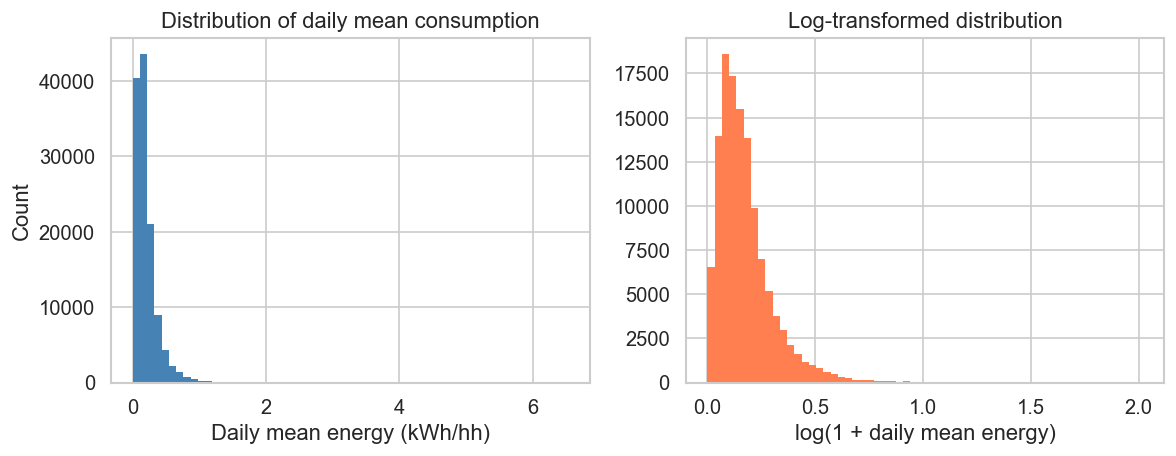

Right-skewed target; log transform gives near-Gaussian shape.


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(daily[TARGET_COL], bins=60, color='steelblue', edgecolor='none')
axes[0].set_xlabel('Daily mean energy (kWh/hh)')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of daily mean consumption')

axes[1].hist(np.log1p(daily[TARGET_COL]), bins=60, color='coral', edgecolor='none')
axes[1].set_xlabel('log(1 + daily mean energy)')
axes[1].set_title('Log-transformed distribution')

plt.tight_layout()
plt.savefig('eda_daily_01_distribution.png', dpi=150)
plt.show()
print('Right-skewed target; log transform gives near-Gaussian shape.')


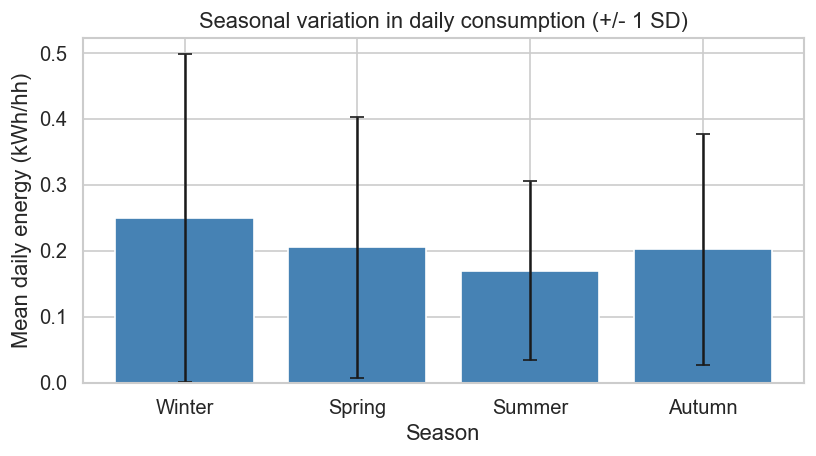

Justifies: season and month as model features.


In [17]:
season_map = {0: 'Winter', 1: 'Spring', 2: 'Summer', 3: 'Autumn'}
daily['season_label'] = daily['season'].map(season_map)
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']

season_profile = (
    daily.groupby('season_label')[TARGET_COL]
    .agg(['mean', 'std'])
    .loc[season_order]
    .reset_index()
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(season_profile['season_label'], season_profile['mean'],
       yerr=season_profile['std'], capsize=4, color='steelblue')
ax.set_xlabel('Season')
ax.set_ylabel('Mean daily energy (kWh/hh)')
ax.set_title('Seasonal variation in daily consumption (+/- 1 SD)')
plt.tight_layout()
plt.savefig('eda_daily_02_season.png', dpi=150)
plt.show()
print('Justifies: season and month as model features.')


C:\Users\2553227\AppData\Local\Temp\ipykernel_20080\2003486466.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=['Weekday', 'Weekend'], showfliers=False)


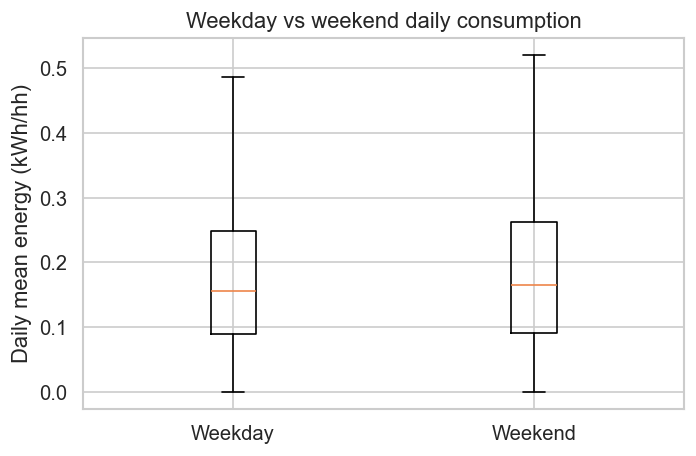

Justifies: is_weekend as a model feature.


In [18]:
daily['day_type'] = daily['is_weekend'].map({0: 'Weekday', 1: 'Weekend'})

fig, ax = plt.subplots(figsize=(6, 4))
groups = [daily.loc[daily['day_type'] == d, TARGET_COL].values for d in ['Weekday', 'Weekend']]
ax.boxplot(groups, labels=['Weekday', 'Weekend'], showfliers=False)
ax.set_ylabel('Daily mean energy (kWh/hh)')
ax.set_title('Weekday vs weekend daily consumption')
plt.tight_layout()
plt.savefig('eda_daily_03_weekend.png', dpi=150)
plt.show()
print('Justifies: is_weekend as a model feature.')


C:\Users\2553227\AppData\Local\Temp\ipykernel_20080\3703071747.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=['Non-holiday', 'Bank holiday'], showfliers=False)


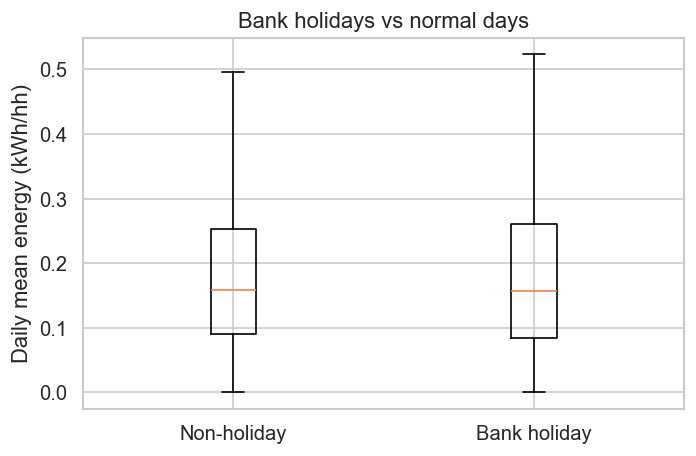

Justifies: is_holiday as a model feature.


In [19]:
daily['hol_label'] = daily['is_holiday'].map({0: 'Non-holiday', 1: 'Bank holiday'})

fig, ax = plt.subplots(figsize=(6, 4))
groups = [daily.loc[daily['hol_label'] == d, TARGET_COL].values for d in ['Non-holiday', 'Bank holiday']]
ax.boxplot(groups, labels=['Non-holiday', 'Bank holiday'], showfliers=False)
ax.set_ylabel('Daily mean energy (kWh/hh)')
ax.set_title('Bank holidays vs normal days')
plt.tight_layout()
plt.savefig('eda_daily_04_holiday.png', dpi=150)
plt.show()
print('Justifies: is_holiday as a model feature.')


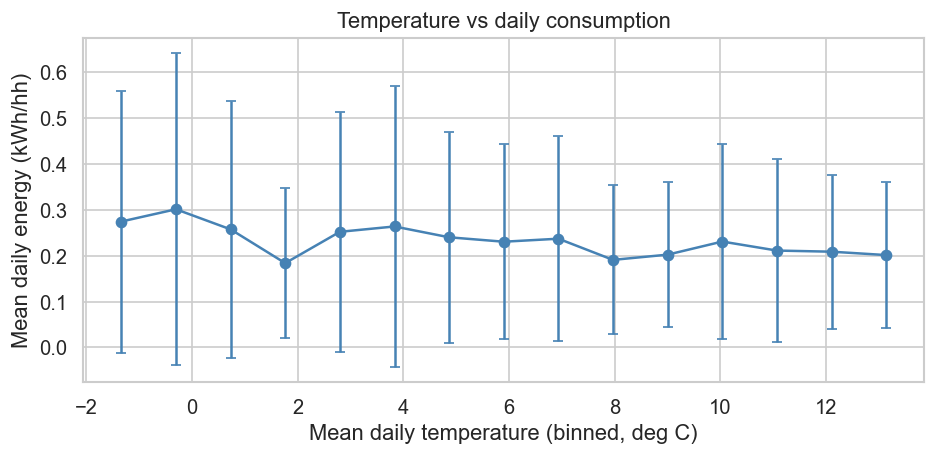

Justifies: temp_avg, temperatureMin, temperatureMax as model features.


In [21]:
temp_bins = pd.cut(daily['temp_avg'], bins=15)
temp_profile = (
    daily.groupby(temp_bins, observed=True)[TARGET_COL]
    .agg(['mean', 'std', 'count'])
    .reset_index()
)
temp_profile['temp_mid'] = temp_profile['temp_avg'].apply(lambda x: x.mid)

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(temp_profile['temp_mid'], temp_profile['mean'],
            yerr=temp_profile['std'], fmt='o-', capsize=3, color='steelblue')
ax.set_xlabel('Mean daily temperature (binned, deg C)')
ax.set_ylabel('Mean daily energy (kWh/hh)')
ax.set_title('Temperature vs daily consumption')
plt.tight_layout()
plt.savefig('eda_daily_05_temperature.png', dpi=150)
plt.show()
print('Justifies: temp_avg, temperatureMin, temperatureMax as model features.')


C:\Users\2553227\AppData\Local\Temp\ipykernel_20080\3274614200.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=acorn_order, showfliers=False)


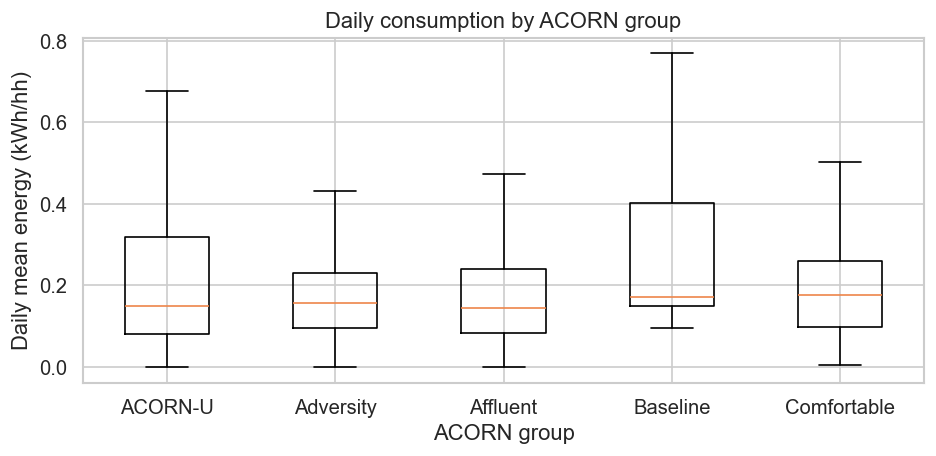

Justifies: ACORN group as a model feature.


In [22]:
acorn_dummies = [c for c in daily.columns if c.startswith('Acorn_grouped_')]

def reconstruct_acorn(row):
    for col in acorn_dummies:
        if row[col]:
            return col.replace('Acorn_grouped_', '')
    return 'Baseline'

daily['acorn_label'] = daily.apply(reconstruct_acorn, axis=1)

acorn_order = sorted(daily['acorn_label'].unique())
groups = [daily.loc[daily['acorn_label'] == a, TARGET_COL].values for a in acorn_order]

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(groups, labels=acorn_order, showfliers=False)
ax.set_xlabel('ACORN group')
ax.set_ylabel('Daily mean energy (kWh/hh)')
ax.set_title('Daily consumption by ACORN group')
plt.tight_layout()
plt.savefig('eda_daily_06_acorn.png', dpi=150)
plt.show()
print('Justifies: ACORN group as a model feature.')


C:\Users\2553227\AppData\Local\Temp\ipykernel_20080\1426869030.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=['Std', 'ToU'], showfliers=False)


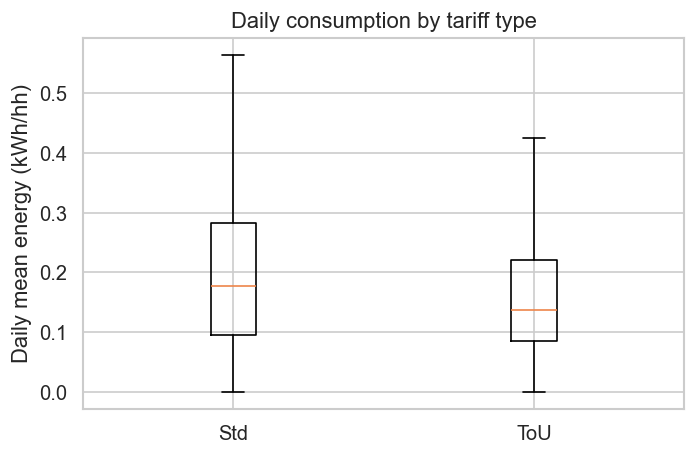

Justifies: tariff type as a model feature.


In [23]:
tou_cols = [c for c in daily.columns if c.startswith('stdorToU_')]
if tou_cols:
    daily['tariff'] = np.where(daily[tou_cols[0]], 'ToU', 'Std')
else:
    daily['tariff'] = 'Std'

groups = [daily.loc[daily['tariff'] == t, TARGET_COL].values for t in ['Std', 'ToU']]
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(groups, labels=['Std', 'ToU'], showfliers=False)
ax.set_ylabel('Daily mean energy (kWh/hh)')
ax.set_title('Daily consumption by tariff type')
plt.tight_layout()
plt.savefig('eda_daily_07_tariff.png', dpi=150)
plt.show()
print('Justifies: tariff type as a model feature.')


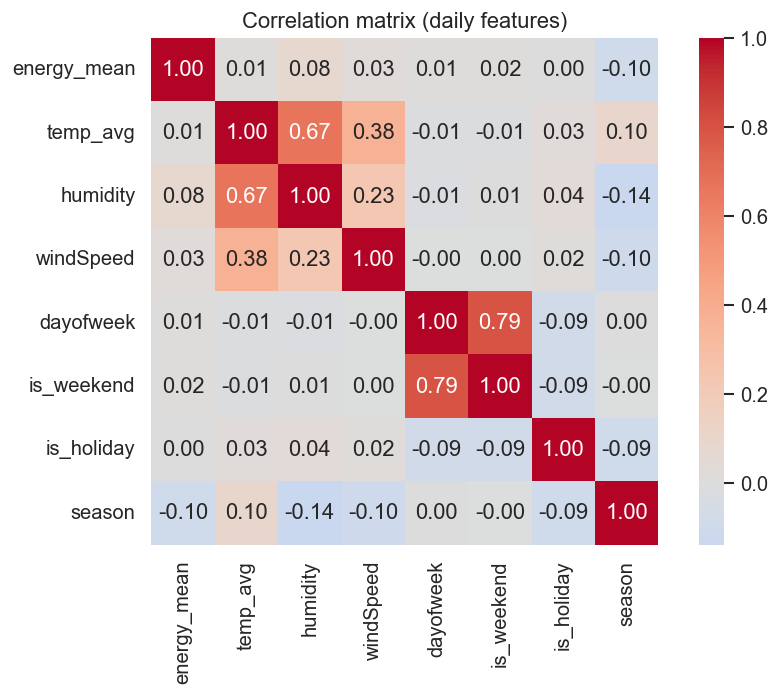


temp_avg should show strongest negative correlation with energy_mean.


In [ ]:
num_cols = [TARGET_COL, 'temp_avg', 'humidity', 'windSpeed',
            'dayofweek', 'is_weekend', 'is_holiday', 'season']
corr = daily[num_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, ax=ax)
ax.set_title('Correlation matrix (daily features)')
plt.tight_layout()
plt.savefig('eda_daily_08_corr.png', dpi=150)
plt.show()
print('\ntemp_avg should show strongest negative correlation with energy_mean.')

---
## 10.10 EDA findings summary

| # | Plot | Key finding | Model implication |
|---|------|-------------|-------------------|
| 1 | Target distribution | Right-skewed; log transform near-Gaussian | Consider log-target or tree models |
| 2 | Seasonal bar chart | Winter >> Summer consumption | `season`, `month` are strong predictors |
| 3 | Weekday vs weekend | Weekend slightly higher | `is_weekend` adds signal |
| 4 | Bank holiday | Lower on holidays | `is_holiday` useful |
| 5 | Temperature scatter | Strong negative relationship | `temperatureMean/Min/Max` essential |
| 6 | ACORN boxplot | Affluent > Comfortable > Adversity | ACORN features justified |
| 7 | Tariff boxplot | ToU households differ in daily usage | Tariff feature justified |
| 8 | Correlation heatmap | Temperature and season dominate | Confirms weather features drive prediction |
